# 02 · Análise RFM — Boto Café ☕

**Objetivo:** descobrir, só olhando o histórico de compras, **quem são os melhores clientes, quem está
esfriando e onde mora o dinheiro** da loja.

> **Analogia:** imagine o dono de uma cafeteria de bairro que reconhece os clientes de cabeça.
> *Recência* é "faz quanto tempo que ele não aparece?", *Frequência* é "quantas vezes vem?" e
> *Monetário* é "quanto deixa no caixa?". O RFM é essa intuição transformada em números —
> para 2.000 clientes de uma vez.

Todo o código reutilizável está em `src/rfm.py`; aqui contamos a história passo a passo.

In [1]:
import sys
from pathlib import Path

# Permite importar o pacote `src` mesmo rodando de dentro de /notebooks
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

from src import rfm as R, config as cfg

# Paleta da marca Boto Café
CAFE, ROSA, VERDE, CREME, OURO = "#3E2723", "#E8A0B4", "#2E5E4E", "#F5EDE0", "#C8963E"
MAPA = LinearSegmentedColormap.from_list("boto", [CREME, OURO, CAFE])
plt.rcParams.update({"figure.facecolor": "white", "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold"})
pd.set_option("display.float_format", "{:,.2f}".format)
brl = lambda v: f"R$ {v:,.0f}".replace(",", ".")

## 1. Carregando e limpando
Lemos o **SQLite** (a fonte da verdade) e tratamos as sujeiras que deixamos de propósito na Fase 1:
e-mails (espaços/caixa alta), cidades (acento/minúsculas) e canal nulo → `"Não informado"`.

**Decisão importante:** o RFM só considera pedidos **válidos** (`pago`, `enviado`, `entregue`).
Cancelado e devolvido não é receita; pendente ainda não foi pago. Se contássemos esses,
um cliente que só cancelou apareceria como "bom comprador".

In [2]:
base = R.carregar_base_limpa()
cli, ped = base["clientes"], base["pedidos"]

print(f"Pedidos totais .....: {len(ped):>7,}")
print(f"Pedidos válidos ....: {ped['valido'].sum():>7,}  ({ped['valido'].mean():.1%})")
print(f"Receita válida .....: {brl(ped.loc[ped['valido'], 'valor_total'].sum())}")
print()
print(ped["status"].value_counts().to_frame("pedidos").T.to_string())

Pedidos totais .....:  15,882
Pedidos válidos ....:  14,860  (93.6%)
Receita válida .....: R$ 4.149.292

status   entregue  cancelado  devolvido  enviado  pago  pendente
pedidos     14589        551        441      206    65        30


## 2. Calculando R, F e M
- **Data de referência** = *o dia seguinte à última compra da base* (08/10/2026). É o "hoje" da análise.
  Usar "hoje" real quebraria a reprodutibilidade; usar o próprio dia da última compra daria recência 0.
- **R** = dias desde a última compra · **F** = nº de pedidos válidos · **M** = soma do valor pago (já descontado).

In [3]:
rfm_bruto, data_ref = R.calcular_rfm(ped)
print(f"Data de referência: {data_ref:%d/%m/%Y}")
print(f"Clientes com pelo menos 1 pedido válido: {len(rfm_bruto):,} de {len(cli):,}")
print(f"→ {len(cli) - len(rfm_bruto)} clientes ficam FORA do RFM (só têm pedidos cancelados/devolvidos/pendentes).")
rfm_bruto[["recencia", "frequencia", "monetario", "ticket_medio"]].describe().T

Data de referência: 08/10/2026
Clientes com pelo menos 1 pedido válido: 1,981 de 2,000
→ 19 clientes ficam FORA do RFM (só têm pedidos cancelados/devolvidos/pendentes).


,count,mean,std,min,25%,50%,75%,max
recencia,"1,981.00",165.04,185.73,1.00,20.00,67.00,278.00,724.00
frequencia,"1,981.00",7.50,9.00,1.00,2.00,4.00,9.00,60.00
monetario,"1,981.00","2,094.54","3,694.27",14.06,402.13,906.99,"2,079.13","28,687.94"
ticket_medio,"1,981.00",225.40,110.89,14.06,153.08,212.17,277.57,"1,204.50"


Repare na **distribuição muito assimétrica**: a média de `monetario` é bem maior que a mediana — poucos clientes
gastam muito. Por isso usamos **quintis** (grupos de 20%) e não faixas fixas: eles se adaptam à forma dos dados.

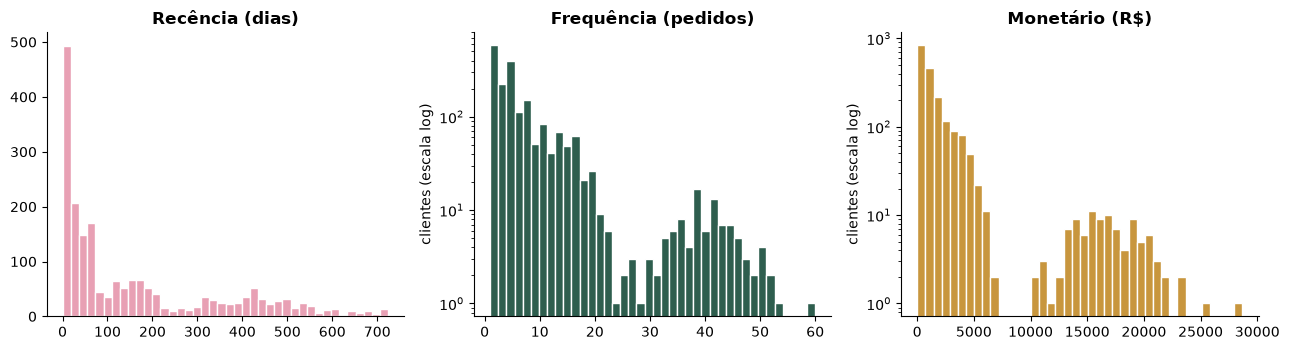

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, col, titulo, cor, log in [
    (axes[0], "recencia", "Recência (dias)", ROSA, False),
    (axes[1], "frequencia", "Frequência (pedidos)", VERDE, True),
    (axes[2], "monetario", "Monetário (R$)", OURO, True),
]:
    ax.hist(rfm_bruto[col], bins=40, color=cor, edgecolor="white")
    ax.set_title(titulo)
    if log:
        ax.set_yscale("log"); ax.set_ylabel("clientes (escala log)")
plt.tight_layout(); plt.show()

## 3. Scores de 1 a 5 (quintis)
- **R:** menor recência = melhor → escala **invertida** (comprou há pouco = 5).
- **F e M:** maior = melhor.
- **Desempate na Frequência:** muitos clientes têm exatamente 1 ou 2 pedidos (empate). Usamos
  `rank(method="first")` antes do `qcut` para dividir os empatados em grupos equilibrados.
  *Trade-off:* dois clientes com a mesma frequência podem receber notas F diferentes — por isso a regra
  "Novos" olha o número real de pedidos, e não só a nota.
- **Score combinado:** texto `"RFM"` (ex.: `545`) e soma (3 a 15).

In [5]:
rfm, base, data_ref = R.construir_rfm()

# Faixas reais que cada nota representa (para o leitor entender o que "R=5" significa)
faixas = []
for metrica, nota in [("recencia", "R"), ("frequencia", "F"), ("monetario", "M")]:
    t = rfm.groupby(nota)[metrica].agg(["min", "max", "count"])
    t.insert(0, "métrica", metrica)
    faixas.append(t)
pd.concat(faixas).rename_axis("nota")

,métrica,min,max,count
nota,,,,
1,recencia,357.00,724.00,397
2,recencia,137.00,355.00,396
3,recencia,48.00,136.00,396
4,recencia,15.00,48.00,396
5,recencia,1.00,15.00,396
1,frequencia,1.00,2.00,397
2,frequencia,2.00,3.00,396
3,frequencia,3.00,5.00,396
4,frequencia,5.00,11.00,396


## 4. Segmentos (as regras)
Os scores sozinhos são difíceis de comunicar ("cliente 534"). Agrupamos em **9 segmentos** com nomes de negócio.
As regras são avaliadas **de cima para baixo** — a primeira que combinar vence — então todo cliente cai
em exatamente um segmento.

In [6]:
R.REGRAS_SEGMENTOS

,segmento,regra,interpretação
0,Campeões,R=5 e F=5 e M=5,"Nota máxima em tudo: compram sempre, muito e a..."
1,Novos,1 único pedido e R>=4,Primeira compra recente: ainda não sabemos que...
2,Clientes Fiéis,R>=3 e F>=4,Compram com frequência e ainda estão ativos.
3,Potenciais Fiéis,R>=4 e F 2–3,"Recentes, com 2+ compras: a um passo de virar ..."
4,Prestes a Dar Churn,R<=2 e F>=3,Já foram bons clientes e estão esfriando: prio...
5,Precisam de Atenção,R=3 e F=3,Meio-termo que pode escorregar se ninguém olhar.
6,Promissores,R>=3 e F<=2 (restante),"Compraram pouco, mas há pouco tempo."
7,Hibernando,R=2 e F<=2,Pouco engajados e já sumindo.
8,Perdidos,R=1 e F<=2,Sem comprar há muito tempo e com pouco histórico.


In [7]:
resumo = R.resumo_segmentos(rfm)
resumo

,clientes,receita,recencia_media,frequencia_media,ticket_medio,% clientes,% receita
segmento,,,,,,,
Campeões,201,"1,841,452.92",6.63,25.90,318.38,10.15,44.38
Clientes Fiéis,457,"1,392,765.02",41.76,11.82,234.12,23.07,33.57
Potenciais Fiéis,221,"157,974.75",19.22,3.24,223.91,11.16,3.81
Novos,68,"11,589.83",29.79,1.00,170.44,3.43,0.28
Promissores,133,"56,453.59",73.74,1.90,223.72,6.71,1.36
Precisam de Atenção,108,"99,778.47",88.96,4.49,204.10,5.45,2.40
Prestes a Dar Churn,322,"412,791.75",269.10,5.75,218.15,16.25,9.95
Hibernando,170,"70,485.15",255.14,2.00,209.12,8.58,1.70
Perdidos,301,"106,000.42",501.07,1.79,188.90,15.19,2.55


## 5. Perguntas de negócio

### P1 · Quem são os clientes VIP (Campeões) e quanto representam da receita?

In [8]:
vip = rfm[rfm["segmento"] == "Campeões"]
receita_total = rfm["monetario"].sum()

print(f"Campeões: {len(vip)} clientes ({len(vip)/len(rfm):.1%} da base) → "
      f"{brl(vip['monetario'].sum())} = {vip['monetario'].sum()/receita_total:.1%} da receita")
print(f"Ticket médio: Campeões {brl(vip['ticket_medio'].mean())} vs. demais {brl(rfm[rfm['segmento']!='Campeões']['ticket_medio'].mean())}")
print(f"Pedidos por Campeão (mediana): {vip['frequencia'].median():.0f} | recência mediana: {vip['recencia'].median():.0f} dias")

# Perfil: onde moram, como chegaram, o que compram, se dependem de cupom
validos = ped[ped["valido"]]
itens = (base["itens_pedido"].merge(validos[["id", "cliente_id", "cupom_usado"]], left_on="pedido_id", right_on="id")
         .merge(base["produtos"][["id", "categoria"]], left_on="produto_id", right_on="id", suffixes=("", "_prod")))
itens["receita_item"] = itens["quantidade"] * itens["preco_unitario"]

def perfil_categoria(ids):
    t = itens[itens["cliente_id"].isin(ids)].groupby("categoria")["receita_item"].sum()
    return (t / t.sum()).rename("% da receita")

perfil = pd.concat({
    "Estado (top 5)": vip["estado"].value_counts(normalize=True).head(5),
    "Canal de aquisição": vip["canal_aquisicao"].value_counts(normalize=True),
    "Categoria (receita)": perfil_categoria(vip.index),
}).rename("participação").to_frame()
perfil["participação"] = (perfil["participação"] * 100).round(1)
perfil

Campeões: 201 clientes (10.1% da base) → R$ 1.841.453 = 44.4% da receita
Ticket médio: Campeões R$ 318 vs. demais R$ 215
Pedidos por Campeão (mediana): 19 | recência mediana: 6 dias


participação
Estado (top 5)      SP                    15.90
                    AM                     9.50
                    PE                     8.00
                    RJ                     8.00
                    CE                     7.00
Canal de aquisição  Instagram             25.40
                    Google                23.40
                    Orgânico              18.40
                    Indicação             17.90
                    Marketplace            8.50
                    TikTok                 4.00
                    Não informado          2.50
Categoria (receita) Acessórios             9.20
                    Assinaturas           25.80
                    Cafeteiras            17.40
                    Grãos                 31.30
                    Kits Presente         16.30

### P2 · Quais clientes estão prestes a abandonar a loja — e quais priorizar?
"Prestes a Dar Churn" = já foram bons (F≥3) e esfriaram (R≤2). Priorizamos pelo **valor em risco**:
quanto esse cliente já nos deu — perder o de R$ 8 mil dói mais que perder o de R$ 400.

In [9]:
churn = rfm[rfm["segmento"] == "Prestes a Dar Churn"].sort_values("monetario", ascending=False)
churn = churn.assign(valor_em_risco_acum=lambda d: d["monetario"].cumsum() / d["monetario"].sum())

print(f"{len(churn)} clientes ({len(churn)/len(rfm):.1%} da base) | histórico de {brl(churn['monetario'].sum())} "
      f"({churn['monetario'].sum()/receita_total:.1%} da receita)")
n80 = int((churn["valor_em_risco_acum"] <= 0.8).sum()) + 1
print(f"→ só {n80} clientes ({n80/len(churn):.0%} do grupo) concentram 80% do valor em risco: é aí que a equipe de CRM deve começar.\n")

churn[["nome", "estado", "recencia", "frequencia", "monetario", "ticket_medio", "score_rfm"]].head(10)

322 clientes (16.3% da base) | histórico de R$ 412.792 (9.9% da receita)
→ só 200 clientes (62% do grupo) concentram 80% do valor em risco: é aí que a equipe de CRM deve começar.



,nome,estado,recencia,frequencia,monetario,ticket_medio,score_rfm
cliente_id,,,,,,,
1245,Lunna Fernandes Cirino,AM,169,10,"5,010.98",501.10,245
1128,Luiz Fernando Santos Novais,SC,175,11,"4,178.72",379.88,255
234,Maria Júlia Andrade Cavalcanti,AC,152,9,"3,901.74",433.53,245
587,Benjamim Pereira Ribeiro,PE,157,9,"3,426.50",380.72,245
1038,Anthony Moura Sousa,SP,194,7,"3,392.38",484.63,245
284,Liam Monteiro Moraes,RS,137,8,"3,387.72",423.47,245
815,Davi Miguel da Costa Pires,SP,161,12,"3,309.69",275.81,255
987,Rael Costa Casa Grande,SP,196,8,"3,181.97",397.75,245
113,Beatriz Ribeiro da Rocha,PI,184,14,"3,142.38",224.46,255


### P3 · Quem são os maiores compradores, que merecem cupom ou recompensa?
Critério: clientes **ativos** (R≥4) e **de alto valor** (M=5). A coluna `% pedidos c/ cupom` ajuda a decidir
o tipo de mimo: quem já compra *sem* cupom merece **brinde/frete/acesso antecipado** (não desconto),
porque dar desconto a quem pagaria cheio é perder margem à toa.

In [10]:
uso_cupom = validos.assign(c=validos["cupom_usado"].notna()).groupby("cliente_id")["c"].mean().mul(100).rename("% pedidos c/ cupom")
top = (rfm[(rfm["R"] >= 4) & (rfm["M"] == 5)].join(uso_cupom)
       .sort_values("monetario", ascending=False))
print(f"{len(top)} clientes ativos de alto valor. Top 10:")
top[["nome", "estado", "segmento", "frequencia", "monetario", "% pedidos c/ cupom"]].head(10)

330 clientes ativos de alto valor. Top 10:


,nome,estado,segmento,frequencia,monetario,% pedidos c/ cupom
cliente_id,,,,,,
342,Enrico Moura Machado,BA,Campeões,60,"28,687.94",13.33
857,Lunna Andrade Pacheco,SE,Campeões,49,"25,406.86",6.12
1090,Nina Mendonça Vasconcelos,BA,Campeões,52,"23,453.80",9.62
1191,Luiz Otávio Carvalho Azevedo,RS,Campeões,52,"23,308.94",13.46
720,Cauã da Mata Garcia,AM,Campeões,47,"21,910.24",12.77
852,Bruna Lopes Rezende,BA,Campeões,53,"21,641.40",1.89
100,Théo Cunha Cassiano,GO,Campeões,51,"21,358.44",9.80
656,Marcelo Machado Aparecida,SP,Clientes Fiéis,43,"21,143.63",6.98
480,Bianca da Mota Aragão,SP,Clientes Fiéis,42,"20,857.25",7.14


### P4 · Receita por segmento e risco de concentração (Pareto)

647 clientes (32.7% da base) geram 80% da receita.
Top 5% da base = 40.3% da receita | Top 10% = 52.2% | Top 20% = 68.0%


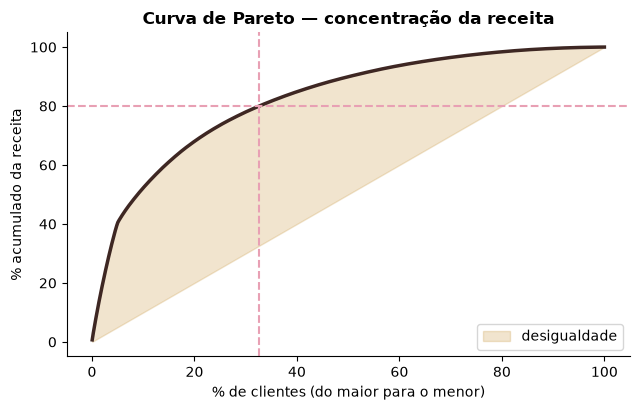

In [11]:
ordenado = rfm.sort_values("monetario", ascending=False)["monetario"].reset_index(drop=True)
acum = ordenado.cumsum() / ordenado.sum()
pct_clientes = (np.arange(1, len(ordenado) + 1)) / len(ordenado)

n80 = int((acum < 0.8).sum()) + 1
print(f"{n80} clientes ({n80/len(ordenado):.1%} da base) geram 80% da receita.")
print(f"Top 5% da base = {acum[int(len(ordenado)*0.05)-1]:.1%} da receita | Top 10% = {acum[int(len(ordenado)*0.10)-1]:.1%} | Top 20% = {acum[int(len(ordenado)*0.20)-1]:.1%}")

fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.plot(pct_clientes * 100, acum * 100, color=CAFE, lw=2.5)
ax.axhline(80, color=ROSA, ls="--"); ax.axvline(n80 / len(ordenado) * 100, color=ROSA, ls="--")
ax.fill_between(pct_clientes * 100, acum * 100, pct_clientes * 100, color=OURO, alpha=.25, label="desigualdade")
ax.set_xlabel("% de clientes (do maior para o menor)"); ax.set_ylabel("% acumulado da receita")
ax.set_title("Curva de Pareto — concentração da receita"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

**Leitura de risco:** quanto mais a curva "se curva", mais a loja depende de poucos clientes. Se os Campeões
reduzirem as compras em 20%, o impacto é desproporcional. A tabela abaixo mostra receita e tamanho lado a lado:

In [12]:
resumo[["clientes", "% clientes", "receita", "% receita", "recencia_media", "frequencia_media"]]

,clientes,% clientes,receita,% receita,recencia_media,frequencia_media
segmento,,,,,,
Campeões,201,10.15,"1,841,452.92",44.38,6.63,25.90
Clientes Fiéis,457,23.07,"1,392,765.02",33.57,41.76,11.82
Potenciais Fiéis,221,11.16,"157,974.75",3.81,19.22,3.24
Novos,68,3.43,"11,589.83",0.28,29.79,1.00
Promissores,133,6.71,"56,453.59",1.36,73.74,1.90
Precisam de Atenção,108,5.45,"99,778.47",2.40,88.96,4.49
Prestes a Dar Churn,322,16.25,"412,791.75",9.95,269.10,5.75
Hibernando,170,8.58,"70,485.15",1.70,255.14,2.00
Perdidos,301,15.19,"106,000.42",2.55,501.07,1.79


### P5 · Qual o potencial de recuperação?
Para cada cliente em **Prestes a Dar Churn** e **Hibernando**, estimamos quanto ele *gastava por ano* enquanto
estava ativo (monetário ÷ dias entre 1ª e última compra × 365, com piso de 90 dias para não inflar quem
comprou duas vezes na mesma semana). Se recuperarmos uma fração, quanto volta?

> Estas taxas são **hipóteses** — na Fase 3 viram parâmetros editáveis com custo do cupom.

In [13]:
alvo = rfm[rfm["segmento"].isin(["Prestes a Dar Churn", "Hibernando"])].copy()
alvo["dias_ativo"] = (alvo["ultima_compra"] - alvo["primeira_compra"]).dt.days.clip(lower=90)
alvo["receita_anual_potencial"] = alvo["monetario"] / alvo["dias_ativo"] * 365

pot = alvo.groupby("segmento", observed=True).agg(
    clientes=("monetario", "size"),
    receita_anual_potencial=("receita_anual_potencial", "sum"),
)
for taxa in (0.10, 0.20, 0.30):
    pot[f"recuperando {taxa:.0%}"] = pot["receita_anual_potencial"] * taxa
pot.loc["TOTAL"] = pot.sum()
pot

,clientes,receita_anual_potencial,recuperando 10%,recuperando 20%,recuperando 30%
segmento,,,,,
Prestes a Dar Churn,322.00,"664,144.85","66,414.48","132,828.97","199,243.45"
Hibernando,170.00,"184,724.90","18,472.49","36,944.98","55,417.47"
TOTAL,492.00,"848,869.74","84,886.97","169,773.95","254,660.92"


## 6. Visualizações
### Mapa de calor R × F
Cada célula = clientes com aquela combinação de notas. O canto superior direito (R alto, F alto) é onde moram
os campeões; o canto inferior esquerdo, os perdidos.

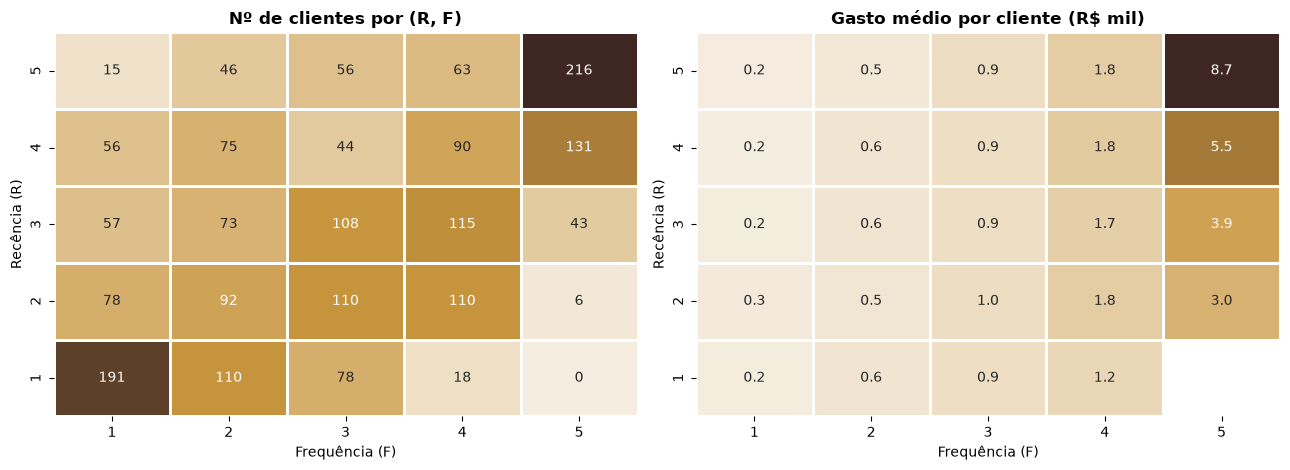

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

cont = rfm.pivot_table(index="R", columns="F", values="monetario", aggfunc="size", fill_value=0).sort_index(ascending=False)
sns.heatmap(cont, annot=True, fmt="d", cmap=MAPA, cbar=False, ax=axes[0], linewidths=2, linecolor="white")
axes[0].set_title("Nº de clientes por (R, F)")

med = rfm.pivot_table(index="R", columns="F", values="monetario", aggfunc="mean").sort_index(ascending=False)
sns.heatmap(med / 1000, annot=True, fmt=".1f", cmap=MAPA, cbar=False, ax=axes[1], linewidths=2, linecolor="white")
axes[1].set_title("Gasto médio por cliente (R$ mil)")
for a in axes:
    a.set_xlabel("Frequência (F)"); a.set_ylabel("Recência (R)")
plt.tight_layout(); plt.show()

### Segmentos: tamanho × receita
O contraste entre as barras é o insight central: **segmentos pequenos pesam muito na receita**.

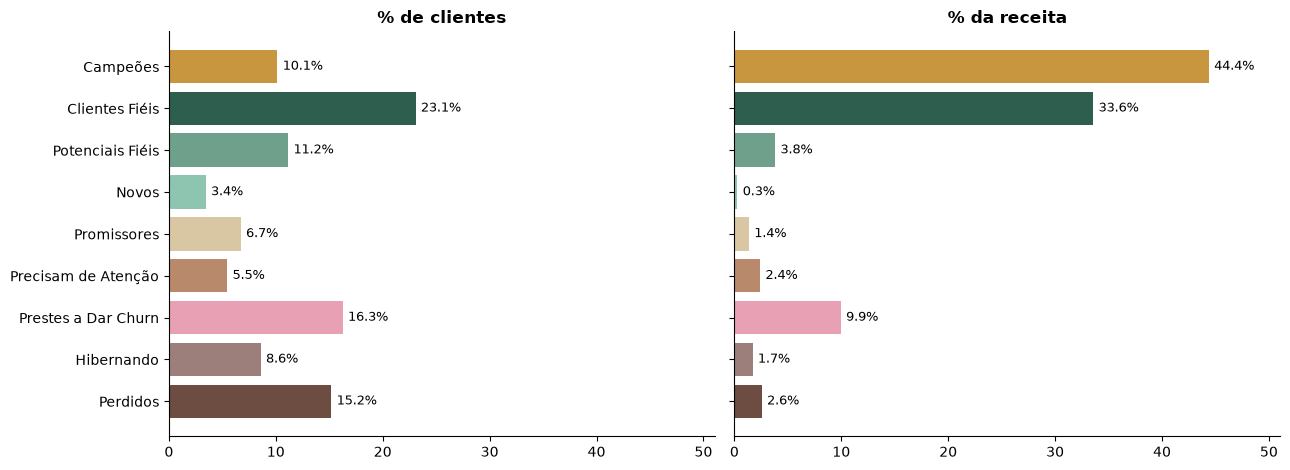

In [15]:
cores = {"Campeões": OURO, "Clientes Fiéis": VERDE, "Potenciais Fiéis": "#6FA08C", "Novos": "#8EC5B0",
         "Promissores": "#D9C7A3", "Precisam de Atenção": "#B8896B", "Prestes a Dar Churn": ROSA,
         "Hibernando": "#9C7F7A", "Perdidos": "#6D4C41"}
ordem = resumo.index[::-1]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, col, titulo in [(axes[0], "% clientes", "% de clientes"), (axes[1], "% receita", "% da receita")]:
    ax.barh(ordem, resumo.loc[ordem, col], color=[cores[s] for s in ordem])
    for y, v in enumerate(resumo.loc[ordem, col]):
        ax.text(v + 0.5, y, f"{v:.1f}%", va="center", fontsize=9)
    ax.set_title(titulo); ax.set_xlim(0, resumo[["% clientes", "% receita"]].max().max() * 1.15)
plt.tight_layout(); plt.show()

### Distribuição dos scores
Por construção, R, F e M têm ~20% em cada nota. O que importa é a **soma**: uma base saudável mostra
muitos clientes nos extremos (campeões e perdidos) e um meio bem povoado.

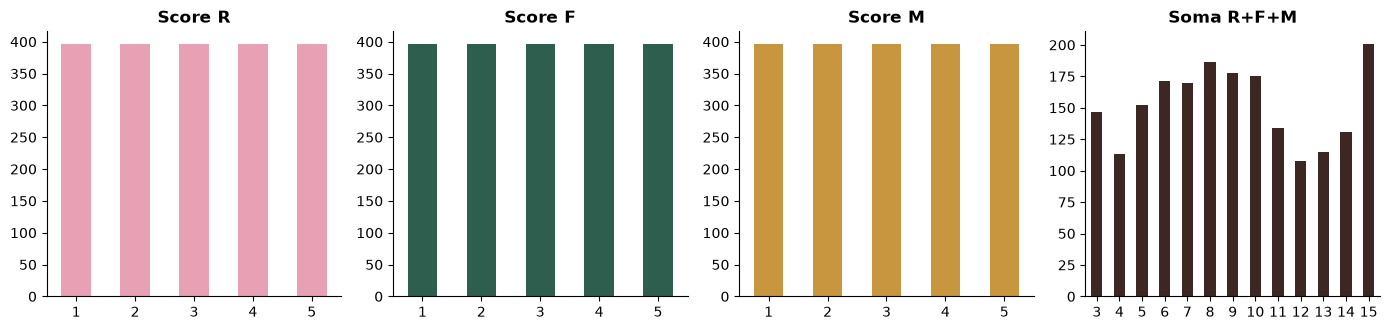

In [16]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4))
for ax, col, cor in zip(axes, ["R", "F", "M", "score_soma"], [ROSA, VERDE, OURO, CAFE]):
    rfm[col].value_counts().sort_index().plot.bar(ax=ax, color=cor, rot=0)
    ax.set_title(f"Score {col}" if col != "score_soma" else "Soma R+F+M"); ax.set_xlabel("")
plt.tight_layout(); plt.show()

## 7. Conferindo com o gabarito (só agora!)
Até aqui **nunca** abrimos `gabarito_perfis.csv`. Agora cruzamos: o RFM, sem ler o roteiro, descobriu quem é quem?
Cada linha soma 100% (para cada perfil real, em quais segmentos o RFM o colocou).

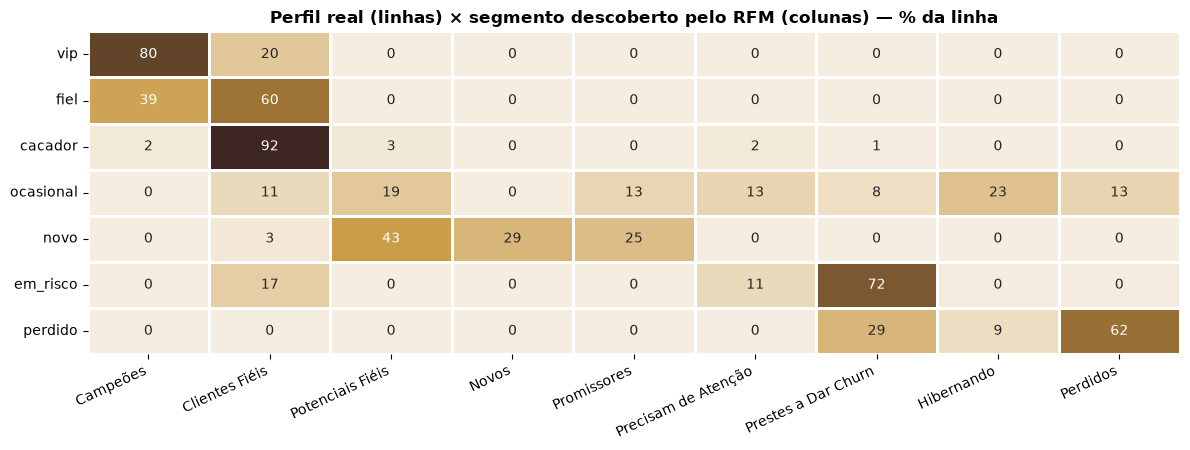

In [17]:
gab = pd.read_csv(cfg.CAMINHO_GABARITO).set_index("cliente_id")
cruz = pd.crosstab(rfm.join(gab)["perfil"], rfm["segmento"], normalize="index") * 100
ordem_perfil = ["vip", "fiel", "cacador", "ocasional", "novo", "em_risco", "perdido"]
cruz = cruz.reindex(ordem_perfil)[[s for s in R.ORDEM_SEGMENTOS if s in cruz.columns]]

fig, ax = plt.subplots(figsize=(12, 4.6))
sns.heatmap(cruz, annot=True, fmt=".0f", cmap=MAPA, cbar=False, ax=ax, linewidths=2, linecolor="white")
ax.set_title("Perfil real (linhas) × segmento descoberto pelo RFM (colunas) — % da linha")
ax.set_xlabel(""); ax.set_ylabel(""); plt.xticks(rotation=25, ha="right")
plt.tight_layout(); plt.show()

**Como ler:** se a diagonal "acende", o RFM acertou. Onde houver mistura (ex.: *ocasional* espalhado por vários
segmentos) não é um erro do método: é que **comportamento parecido gera notas parecidas**, mesmo vindo de
"personagens" diferentes — RFM descreve *o que o cliente fez*, não *quem ele é*.

**Limitação que descobrimos (e que vale citar na entrevista):** os quintis dividem a base em 20% fixos, então
**VIPs (~40 pedidos) e fiéis (~15 pedidos) caem juntos no topo da Frequência**. Na primeira versão a regra de
Campeões era "R, F e M ≥ 4" e o segmento ficou com **24% dos clientes e 69% da receita** — largo demais para
ser acionável. Apertamos para **nota máxima nos três eixos (5-5-5)**. Mesmo assim, o RFM não separa 100%
VIP de fiel; para isso seria preciso usar valores absolutos (ex.: F ≥ 25 pedidos) em vez de quintis.

## 8. Exportando para as próximas fases
O arquivo `data/rfm_clientes.csv` alimenta o notebook de cupons (Fase 3), o dashboard (Fase 4) e o Power BI (Fase 5).

In [18]:
saida = rfm.reset_index()
saida["segmento"] = saida["segmento"].astype(str)
saida.to_csv(R.CAMINHO_RFM, index=False, encoding="utf-8")
print(f"✅ {len(saida):,} clientes → {R.CAMINHO_RFM.relative_to(cfg.RAIZ)}")
saida.head(3)

✅ 1,981 clientes → data\rfm_clientes.csv


,cliente_id,nome,email,cidade,estado,data_cadastro,canal_aquisicao,ultima_compra,primeira_compra,frequencia,monetario,recencia,ticket_medio,R,F,M,score_rfm,score_soma,segmento
0,1,Sophie Alves Gonçalves,sophiealvesgoncalves@example.com,Ananindeua,PA,2024-10-07,Google,2026-05-23,2024-10-08,5,"1,083.18",138,216.64,2,3,3,233,8,Prestes a Dar Churn
1,2,Gael Henrique Rodrigues Freitas,gael.henrique.rodrigues.freitas@example.com,Recife,PE,2024-10-07,Google,2026-09-27,2024-10-07,13,"2,994.06",11,230.31,5,5,5,555,15,Campeões
2,3,Jade Almeida Duarte,jade_almeida_duarte@example.com,Niterói,RJ,2024-10-07,Instagram,2026-08-06,2024-10-08,3,"1,331.71",63,443.90,3,2,4,324,9,Promissores
